In [9]:
from _challenge_catalog import get_challenge_infos
from _starter_core import DEFAULT_API_BASE, print_open_challenge_infos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [10]:

# Fetch and display open challenges using the default API base
api_base = DEFAULT_API_BASE
challenge_infos = get_challenge_infos(api_base, arena_api_key=None)
print_open_challenge_infos(challenge_infos, api_base=api_base, arena_api_key=None)

Challenge ID  Target            Area      Forecast Format               Next Submission Deadline   Next Target Start        
------------  ----------------  --------  ----------------------------  -------------------------  -------------------------
1             Day-Ahead Prices  AT        point                         2026-11-01T12:00:00+01:00  2026-11-02T00:00:00+01:00
7             Day-Ahead Prices  AT        [q2.5, q25, q50, q75, q97.5]  2026-11-01T12:00:00+01:00  2026-11-02T00:00:00+01:00
13            Day-Ahead Prices  AT        [e1, ..., e100]               2026-11-01T12:00:00+01:00  2026-11-02T00:00:00+01:00
31            Day-Ahead Prices  BE        point                         2026-11-01T12:00:00+01:00  2026-11-02T00:00:00+01:00
32            Day-Ahead Prices  BE        [q2.5, q25, q50, q75, q97.5]  2026-11-01T12:00:00+01:00  2026-11-02T00:00:00+01:00
33            Day-Ahead Prices  BE        [e1, ..., e100]               2026-11-01T12:00:00+01:00  2026-11-02T00:00:00+01:00


In [11]:
print("Available challenge IDs:", list(challenge_infos.keys()))

Available challenge IDs: ['generated_at', 'active_challenges']


In [12]:
import os
from datetime import date
from dotenv import load_dotenv
from data_loaders import load_source_series
from _starter_core import _resolve_challenge_context, DEFAULT_API_BASE

# 1. Load variables from your .env file
load_dotenv()
api_key = os.getenv("ENTSOE_API_KEY")

print("API Key loaded successfully:", "Yes" if api_key else "No")

# 2. Resolve ChallengeContext for Challenge 2 (DE_LU Day-Ahead Prices)
challenge_context = _resolve_challenge_context(
    api_base=DEFAULT_API_BASE,
    challenge_id="2",  # Challenge 2 uses "DE_LU", which entsoe-py natively accepts
    area=None,
    arena_api_key=None
)

# 3. Define delivery_date as a proper date object
delivery_date = date(2026, 11, 1)

# 4. Call load_source_series with ENTSO-E
series = load_source_series(
    data_source="entsoe",
    challenge_context=challenge_context,
    delivery_date=delivery_date,
    entsoe_api_key=api_key
)

# 5. Inspect the resulting pandas Series
print("\nLoaded ENTSO-E Series Preview:")
print(series.head())

API Key loaded successfully: Yes

Loaded ENTSO-E Series Preview:
2026-11-01 00:00:00+01:00    257.39
2026-11-01 00:15:00+01:00    251.04
2026-11-01 00:30:00+01:00    239.71
2026-11-01 00:45:00+01:00    235.00
2026-11-01 01:00:00+01:00    251.50
dtype: float64


In [13]:
import os
from datetime import date
from dotenv import load_dotenv
from data_loaders import load_source_series
from _starter_core import _resolve_challenge_context, DEFAULT_API_BASE
import pandas as pd

def load_data_by_challenge(challenge_id: str, delivery_date: date) -> pd.Series:
    """
    Automatically resolves challenge metadata, maps area codes for ENTSO-E compatibility,
    and returns the loaded pandas Series.
    """
    # 1. Load environment variables
    load_dotenv()
    api_key = os.getenv("ENTSOE_API_KEY")
    if not api_key:
        raise RuntimeError("ENTSOE_API_KEY is missing from your .env file.")

    # 2. Resolve the challenge context automatically from the API
    challenge_context = _resolve_challenge_context(
        api_base=DEFAULT_API_BASE,
        challenge_id=str(challenge_id),
        area=None,
        arena_api_key=None
    )

    # 3. Map Energy Arena area codes to entsoe-py expected formats
    entsoe_area_mapping = {
        "DK1": "DK_1",
        "DK2": "DK_2",
    }
    
    resolved_area = entsoe_area_mapping.get(challenge_context.area, challenge_context.area)
    if resolved_area != challenge_context.area:
        object.__setattr__(challenge_context, "area", resolved_area)

    # 4. Load the source series using ENTSO-E
    series = load_source_series(
        data_source="entsoe",
        challenge_context=challenge_context,
        delivery_date=delivery_date,
        entsoe_api_key=api_key
    )

    print(f"Successfully loaded data for Challenge {challenge_id} ({challenge_context.target_name}) in area {resolved_area}")
    return series

In [14]:
from entsoe.mappings import lookup_area
from entsoe import Area

# Test looking up valid country codes or EIC strings
print(lookup_area("DE_LU"))
print(lookup_area("DK_1"))


10Y1001A1001A82H
10YDK-1--------W


In [15]:

# Or iterate through the Area Enum to see all supported zones
for area in Area:
    print(area.name, "->", area.value)

DE_50HZ -> 10YDE-VE-------2
AL -> 10YAL-KESH-----5
DE_AMPRION -> 10YDE-RWENET---I
AT -> 10YAT-APG------L
BY -> 10Y1001A1001A51S
BE -> 10YBE----------2
BA -> 10YBA-JPCC-----D
BG -> 10YCA-BULGARIA-R
CZ_DE_SK -> 10YDOM-CZ-DE-SKK
HR -> 10YHR-HEP------M
CWE -> 10YDOM-REGION-1V
CY -> 10YCY-1001A0003J
CZ -> 10YCZ-CEPS-----N
DE_AT_LU -> 10Y1001A1001A63L
DE_LU -> 10Y1001A1001A82H
DK -> 10Y1001A1001A65H
DK_1 -> 10YDK-1--------W
DK_1_NO_1 -> 46Y000000000007M
DK_2 -> 10YDK-2--------M
DK_CA -> 10Y1001A1001A796
EE -> 10Y1001A1001A39I
FI -> 10YFI-1--------U
MK -> 10YMK-MEPSO----8
FR -> 10YFR-RTE------C
DE -> 10Y1001A1001A83F
GR -> 10YGR-HTSO-----Y
HU -> 10YHU-MAVIR----U
IS -> IS
IE_SEM -> 10Y1001A1001A59C
IE -> 10YIE-1001A00010
NIE -> 10Y1001A1001A016
IT -> 10YIT-GRTN-----B
IT_SACO_AC -> 10Y1001A1001A885
IT_CALA -> 10Y1001C--00096J
IT_SACO_DC -> 10Y1001A1001A893
IT_BRNN -> 10Y1001A1001A699
IT_CNOR -> 10Y1001A1001A70O
IT_CSUD -> 10Y1001A1001A71M
IT_FOGN -> 10Y1001A1001A72K
IT_GR -> 10Y1001A1001A66F
IT

## ENSTOE API

In [ ]:
import os
from dotenv import load_dotenv
from entsoe import EntsoePandasClient
import pandas as pd


In [18]:
#client.query_wind_and_solar_forecast(country_code = country_code, start=start, end=end)

In [121]:
import os
import pandas as pd
from dotenv import load_dotenv
from entsoe import EntsoePandasClient

def fetch_entsoe_market_data(start: pd.Timestamp, end: pd.Timestamp, country_code: str = "DK_1") -> pd.DataFrame:
    """
    Queries ENTSO-E for generation mix, total load, and day-ahead prices,
    then aligns and merges them into a single master DataFrame.
    """
    load_dotenv()
    api_key = os.getenv("ENTSOE_API_KEY")
    if not api_key:
        raise ValueError("ENTSOE_API_KEY is not found in your environment or .env file.")

    client = EntsoePandasClient(api_key=api_key)

    print(f"Fetching data for {country_code} from {start} to {end}...")
    
    # 1. Query raw datasets
    generation_df = client.query_generation(country_code=country_code, start=start, end=end)
    load_df = client.query_load(country_code=country_code, start=start, end=end)
    prices_df = client.query_day_ahead_prices(country_code=country_code, start=start, end=end)

    # 2. Extract series safely
    prices_series = prices_df.iloc[:, 0] if isinstance(prices_df, pd.DataFrame) else prices_df
    load_series = load_df.iloc[:, 0] if isinstance(load_df, pd.DataFrame) else load_df

    # 3. Establish master index based on highest available frequency or standard hourly anchor
    # Using an outer join or reindexing protects against dropping high-resolution data.
    df_master = pd.DataFrame(index=prices_series.index)
    df_master['price'] = prices_series
    
    # Resample or reindex load to match the base index safely
    df_master['load'] = load_series.reindex(df_master.index, method='nearest')

    # 4. Integrate generation columns dynamically with safe alignment
    if isinstance(generation_df, pd.DataFrame):
        for col in generation_df.columns:
            gen_series = generation_df[col]
            df_master[col] = gen_series.reindex(df_master.index, method='nearest')
    else:
        df_master['generation'] = generation_df.reindex(df_master.index, method='nearest')

    # 5. Handle missing values (e.g., zero solar at night)
    df_master = df_master.fillna(0)

    print(f"Unified Dataset Compiled Successfully. Shape: {df_master.shape}")
    return df_master

# --- Execution Example ---
if __name__ == "__main__":
    start_ts = pd.Timestamp("2026-01-01 00:00", tz="UTC")
    end_ts = pd.Timestamp("2026-10-31 23:59", tz="UTC")
    
    master_data = fetch_entsoe_market_data(start=start_ts, end=end_ts, country_code="DK_1")
    display(master_data.head())

Fetching data for DK_1 from 2026-01-01 00:00:00+00:00 to 2026-10-31 23:59:00+00:00...
Unified Dataset Compiled Successfully. Shape: (29184, 12)


,price,load,Biomass,Fossil Gas,Fossil Hard coal,Fossil Oil,Hydro Run-of-river and pondage,Other renewable,Solar,Waste,Wind Offshore,Wind Onshore
2026-01-01 01:00:00+01:00,60.01,2588.7250,208.926,1.64867,106.901,3.04131,1.09,1.19,11.4925,72.8499,1919.19,2813.31
2026-01-01 01:15:00+01:00,48.90,2588.7250,226.815,4.31170,110.451,3.08622,1.09,1.12,11.4286,70.8186,1923.89,2886.50
2026-01-01 01:30:00+01:00,36.74,2674.8475,238.411,6.83906,111.338,3.20065,1.09,1.16,11.3913,67.6977,1924.55,2930.04
2026-01-01 01:45:00+01:00,23.93,2674.8475,216.385,4.56957,106.901,2.77686,1.09,1.19,11.3131,64.8583,1922.59,2991.12
2026-01-01 02:00:00+01:00,36.01,2674.8475,212.172,8.08108,103.708,2.84407,1.09,1.18,11.4723,60.5302,1923.41,3008.27


In [25]:
import torch
print("PyTorch Version:", torch.__version__)

PyTorch Version: 2.15.0+cpu


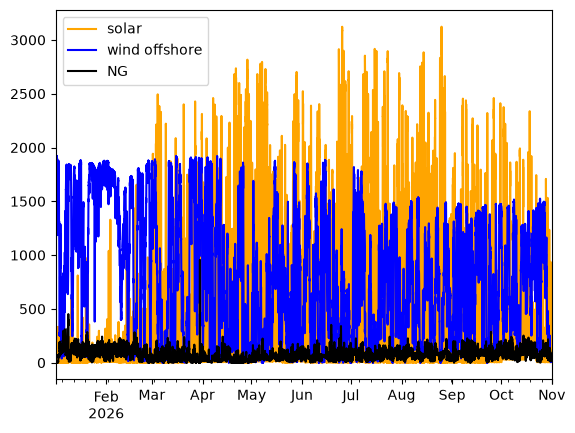

In [122]:

(master_data["Solar"]).plot(color = "orange", label = "solar")
(master_data["Wind Offshore"]).plot(color = "blue", label ="wind offshore")
(master_data["Fossil Gas"]).plot(color = "black", label = "NG")
plt.legend()

<Axes: >

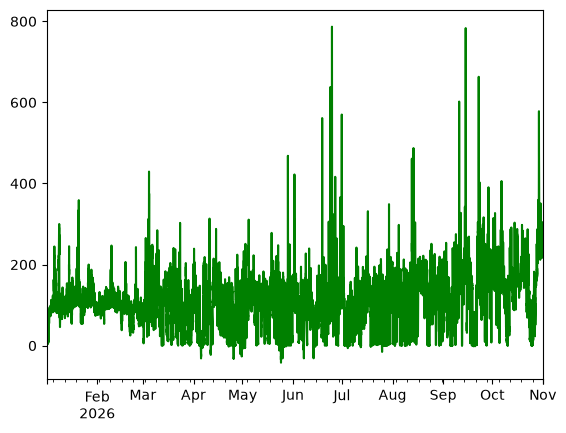

In [123]:
master_data["price"].plot(color = "green")

In [90]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_error, mean_squared_error
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

 ## Simple Neural Network Model

In [225]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.preprocessing import StandardScaler

# 1. Ensure master_data is loaded and indexed correctly
# (Assumes master_data DataFrame with columns: "Solar", "Wind Offshore", "Fossil Gas", "price")
feature_cols =  ["Wind Offshore", "Fossil Gas", "Wind Onshore"]
target_col = "price"

X = master_data[feature_cols].values
y = master_data[target_col].values

# 2. Control Training and Testing Windows for 15-Minute Data
steps_per_hour = 4  # 60 mins / 15 mins
test_horizon = 1 * 24 * steps_per_hour      # Exactly the last 7 days (672 steps)
max_train_size = 5 * 24 * steps_per_hour  # Optional: Restrict training to the last 30 days (2,880 steps), or set to None

# Isolate test indices at the very end of the dataset
test_start_idx = len(X) - test_horizon
train_indices = np.arange(0, test_start_idx)

# Apply optional training window cap from the most recent historical data backwards
if max_train_size is not None and len(train_indices) > max_train_size:
    train_indices = train_indices[-max_train_size:]

test_indices = np.arange(test_start_idx, len(X))

X_train, y_train = X[train_indices], y[train_indices]
X_test, y_test = X[test_indices], y[test_indices]

print(f"Training Window: {len(X_train)} steps ({len(X_train)/steps_per_hour/24:.1f} days)")
print(f"Testing Window:  {len(X_test)} steps ({len(X_test)/steps_per_hour/24:.1f} days)")

# 3. Scale Features and Targets Independently
scaler_x = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_x.fit_transform(X_train)
X_test_scaled = scaler_x.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1))
# Keep y_test unscaled to calculate error metrics directly in €/MWh

# 4. Convert to PyTorch Tensors
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)

# 5. Define Simple Neural Network Architecture
class SimplePricePredictor(nn.Module):
    def __init__(self, input_dim):
        super(SimplePricePredictor, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )
    def forward(self, x):
        return self.net(x)

model = SimplePricePredictor(input_dim=X.shape[1])
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.005)

# 6. Training Loop
model.train()
for epoch in range(100):
    optimizer.zero_grad()
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()

# 7. Evaluate on the Last 7 Days
model.eval()
with torch.no_grad():
    preds_scaled = model(X_test_t)
    preds = scaler_y.inverse_transform(preds_scaled.numpy()).flatten()
    
    # Calculate Root Mean Squared Error and Mean Absolute Error in €/MWh
    rmse = np.sqrt(np.mean((preds - y_test) ** 2))
    mae = np.mean(np.abs(preds - y_test))

print(f"\nTest Evaluation Results:")
print(f"Test RMSE: {rmse:.2f} €/MWh")
print(f"Test MAE:  {mae:.2f} €/MWh")

Training Window: 480 steps (5.0 days)
Testing Window:  96 steps (1.0 days)

Test Evaluation Results:
Test RMSE: 25.83 €/MWh
Test MAE:  17.70 €/MWh


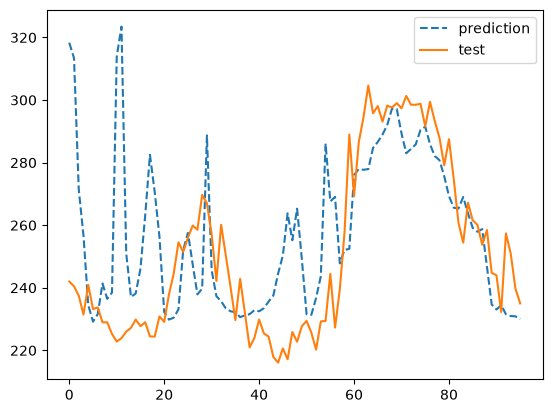

In [226]:
plt.plot(preds, label = "prediction", linestyle = "--")
plt.plot(y_test, label = "test")
plt.legend()

## Adding Lagged Features

In [241]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.preprocessing import StandardScaler

# 1. Construct Feature Matrix with Lags
# 15-minute resolution: 1 step = 15 mins, 4 steps = 1 hour, 96 steps = 24 hours
df_feat = master_data[["Solar", "Wind Offshore", "Fossil Gas", "price"]].copy()

df_feat["price_lag_1"] = df_feat["price"].shift(1)   # 15 minutes ago
df_feat["price_lag_4"] = df_feat["price"].shift(4)   # 1 hour ago
df_feat["price_lag_96"] = df_feat["price"].shift(96) # 24 hours ago

df_feat["wind_lag_4"] = df_feat["Wind Offshore"].shift(4)
df_feat["solar_lag_4"] = df_feat["Solar"].shift(4)

# Drop initial rows containing NaNs created by shifting
df_feat = df_feat.dropna()

feature_cols = [
    "Solar", "Wind Offshore", "Fossil Gas", 
    "price_lag_1", "price_lag_4", "price_lag_96", 
    "wind_lag_4", "solar_lag_4"
]
target_col = "price"

X = df_feat[feature_cols].values
y = df_feat[target_col].values

# 2. Control Training and Testing Windows
steps_per_hour = 4
test_horizon = 24 * steps_per_hour      # Last 24 hours (96 steps) for quick evaluation
max_train_size = 5 * 24 * steps_per_hour  # 5 days of training history (480 steps)

test_start_idx = len(X) - test_horizon
train_indices = np.arange(0, test_start_idx)

if max_train_size is not None and len(train_indices) > max_train_size:
    train_indices = train_indices[-max_train_size:]

test_indices = np.arange(test_start_idx, len(X))

X_train, y_train = X[train_indices], y[train_indices]
X_test, y_test = X[test_indices], y[test_indices]

print(f"Training Window: {len(X_train)} steps ({len(X_train)/steps_per_hour/24:.1f} days)")
print(f"Testing Window:  {len(X_test)} steps ({len(X_test)/steps_per_hour/24:.1f} days)")

# 3. Scale Features and Targets Independently
scaler_x = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_x.fit_transform(X_train)
X_test_scaled = scaler_x.transform(X_test)
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1))

# 4. Convert to PyTorch Tensors
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)

# 5. Flexible Neural Network with LeakyReLU
class FlexiblePricePredictor(nn.Module):
    def __init__(self, input_dim):
        super(FlexiblePricePredictor, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.LeakyReLU(),
            nn.Linear(64, 32),
            nn.LeakyReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.net(x)

model = FlexiblePricePredictor(input_dim=X.shape[1])
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.005)

# 6. Training Loop
model.train()
for epoch in range(150):
    optimizer.zero_grad()
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()

# 7. Evaluate on Test Set
model.eval()
with torch.no_grad():
    preds_scaled = model(X_test_t)
    preds = scaler_y.inverse_transform(preds_scaled.numpy()).flatten()
    
    rmse = np.sqrt(np.mean((preds - y_test) ** 2))
    mae = np.mean(np.abs(preds - y_test))

print(f"\nTest Evaluation Results:")
print(f"Test RMSE: {rmse:.2f} €/MWh")
print(f"Test MAE:  {mae:.2f} €/MWh")

Training Window: 480 steps (5.0 days)
Testing Window:  96 steps (1.0 days)

Test Evaluation Results:
Test RMSE: 10.09 €/MWh
Test MAE:  7.38 €/MWh


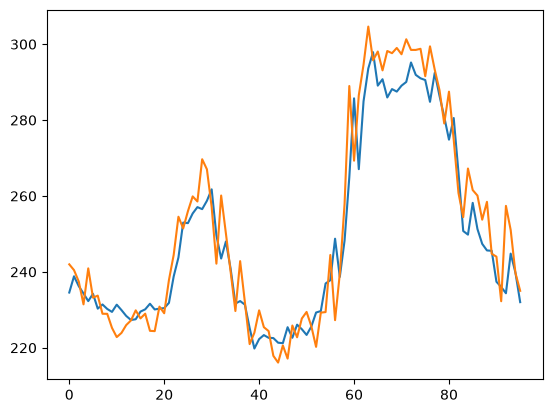

In [234]:
plt.plot(preds)
plt.plot(y_test)

In [236]:
end_ts = pd.Timestamp("2026-11-01 10:00", tz="UTC")
start_ts = pd.Timestamp("2026-10-31 23:59", tz="UTC")
    
DA_data = fetch_entsoe_market_data(start=start_ts, end=end_ts, country_code="DK_1")
display(DA_data.head())

Fetching data for DK_1 from 2026-10-31 23:59:00+00:00 to 2026-11-01 10:00:00+00:00...
Unified Dataset Compiled Successfully. Shape: (41, 10)


,price,load,Biomass,Fossil Gas,Fossil Hard coal,Fossil Oil,Solar,Waste,Wind Offshore,Wind Onshore
2026-11-01 01:00:00+01:00,251.50,2264.17,147.168,26.7656,209.932,1.61055,4.00713,88.1990,56.9054,166.149
2026-11-01 01:15:00+01:00,243.85,2264.17,138.495,20.5634,210.853,1.61220,3.99763,88.5031,60.6814,161.902
2026-11-01 01:30:00+01:00,242.64,2264.17,139.341,17.7503,210.451,1.61352,4.11706,89.0176,56.9013,161.722
2026-11-01 01:45:00+01:00,239.87,2264.17,166.483,21.7463,210.533,1.62620,4.30105,90.1115,64.8055,166.184
2026-11-01 02:00:00+01:00,251.39,2264.17,179.170,23.2611,210.870,1.65171,4.38405,90.7956,69.1686,173.061


<Axes: >

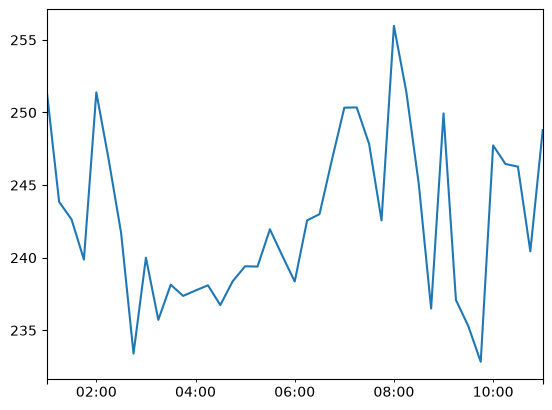

In [239]:
DA_data["price"].plot()


Running recursive forecast for 41 steps of November 1st...

November 1st Evaluation Results (Up to 10:00 AM):
RMSE: 6.93 €/MWh
MAE:  4.77 €/MWh


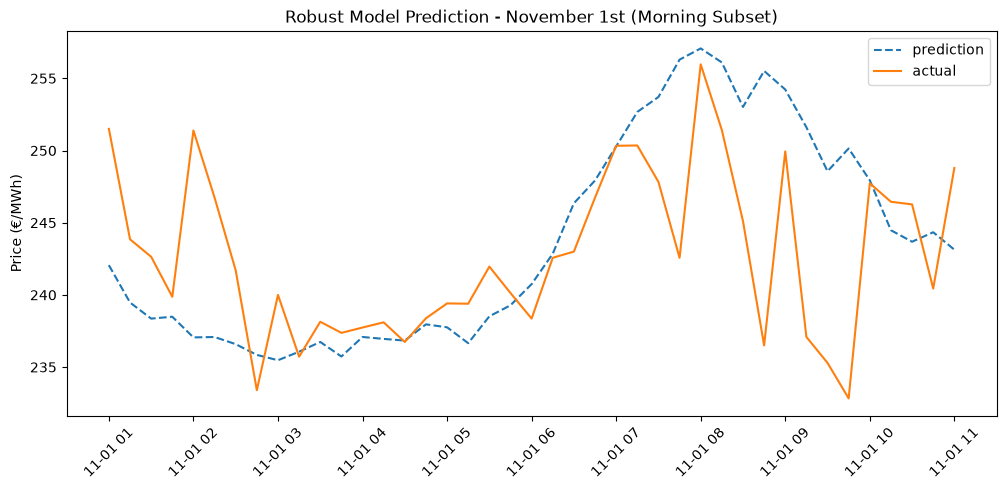

In [246]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# 1. Advanced Feature Engineering with Rolling Trends and Volatility on Master Data
df_feat = master_data[["Solar", "Wind Offshore", "Fossil Gas", "price"]].copy()

# Discrete Lags
df_feat["price_lag_1"] = df_feat["price"].shift(1)
df_feat["price_lag_4"] = df_feat["price"].shift(4)
df_feat["price_lag_96"] = df_feat["price"].shift(96)
df_feat["wind_lag_4"] = df_feat["Wind Offshore"].shift(4)
df_feat["solar_lag_4"] = df_feat["Solar"].shift(4)

# Rolling Momentum Features
df_feat["price_rolling_mean_4"] = df_feat["price"].shift(1).rolling(window=4).mean()
df_feat["price_rolling_std_4"] = df_feat["price"].shift(1).rolling(window=4).std()
df_feat["wind_rolling_mean_4"] = df_feat["Wind Offshore"].shift(1).rolling(window=4).mean()

df_feat = df_feat.dropna()

feature_cols = [
    "Solar", "Wind Offshore", "Fossil Gas", 
    "price_lag_1", "price_lag_4", "price_lag_96", 
    "wind_lag_4", "solar_lag_4",
    "price_rolling_mean_4", "price_rolling_std_4", "wind_rolling_mean_4"
]
target_col = "price"

X = df_feat[feature_cols].values
y = df_feat[target_col].values

# 2. Control Training Window (Using last 10 days for stable regime training)
steps_per_hour = 4
max_train_size = 10 * 24 * steps_per_hour  # 960 steps

train_indices = np.arange(0, len(X))
if max_train_size is not None and len(train_indices) > max_train_size:
    train_indices = train_indices[-max_train_size:]

X_train, y_train = X[train_indices], y[train_indices]

# 3. Scale Features and Targets Independently
scaler_x = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_x.fit_transform(X_train)
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1))

# 4. Convert to PyTorch Tensors
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train_scaled, dtype=torch.float32)

# 5. Define Robust Neural Network Architecture
class RobustPricePredictor(nn.Module):
    def __init__(self, input_dim):
        super(RobustPricePredictor, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.LayerNorm(64),
            nn.LeakyReLU(),
            nn.Dropout(0.1),
            nn.Linear(64, 32),
            nn.LayerNorm(32),
            nn.LeakyReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.net(x)

model = RobustPricePredictor(input_dim=X.shape[1])
criterion = nn.HuberLoss(delta=1.0)
optimizer = optim.AdamW(model.parameters(), lr=0.003, weight_decay=1e-4)

# 6. Training Loop
model.train()
for epoch in range(200):
    optimizer.zero_grad()
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()

# 7. Recursive Forecasting on November 1st Morning Dataset (DA_data)
# Combine master data with DA_data to ensure continuous rolling history
eval_combined = pd.concat([master_data, DA_data])
eval_combined = eval_combined[~eval_combined.index.duplicated(keep='last')]

df_eval_feat = eval_combined[["Solar", "Wind Offshore", "Fossil Gas", "price"]].copy()
df_eval_feat["price_lag_1"] = df_eval_feat["price"].shift(1)
df_eval_feat["price_lag_4"] = df_eval_feat["price"].shift(4)
df_eval_feat["price_lag_96"] = df_eval_feat["price"].shift(96)
df_eval_feat["wind_lag_4"] = df_eval_feat["Wind Offshore"].shift(4)
df_eval_feat["solar_lag_4"] = df_eval_feat["Solar"].shift(4)

df_eval_feat["price_rolling_mean_4"] = df_eval_feat["price"].shift(1).rolling(window=4).mean()
df_eval_feat["price_rolling_std_4"] = df_eval_feat["price"].shift(1).rolling(window=4).std()
df_eval_feat["wind_rolling_mean_4"] = df_eval_feat["Wind Offshore"].shift(1).rolling(window=4).mean()

nov_target_rows = DA_data.index
history_buffer = df_eval_feat.loc[:nov_target_rows[0]].iloc[-96:].copy()

predictions = []
actuals = []

print(f"\nRunning recursive forecast for {len(nov_target_rows)} steps of November 1st...")

model.eval()
for timestamp in nov_target_rows:
    row = DA_data.loc[timestamp]
    solar = row["Solar"]
    wind = row["Wind Offshore"]
    gas = row["Fossil Gas"]
    actual_price = row["price"]
    
    # Extract features matching the 11-column feature_cols definition
    p_lag_1 = history_buffer["price"].iloc[-1]
    p_lag_4 = history_buffer["price"].iloc[-4]
    p_lag_96 = history_buffer["price"].iloc[-96]
    wind_lag_4 = history_buffer["Wind Offshore"].iloc[-4]
    solar_lag_4 = history_buffer["Solar"].iloc[-4]
    
    p_roll_mean_4 = history_buffer["price"].iloc[-4:].mean()
    p_roll_std_4 = history_buffer["price"].iloc[-4:].std()
    wind_roll_mean_4 = history_buffer["Wind Offshore"].iloc[-4:].mean()
    
    x_input = np.array([[
        solar, wind, gas, 
        p_lag_1, p_lag_4, p_lag_96, 
        wind_lag_4, solar_lag_4,
        p_roll_mean_4, p_roll_std_4, wind_roll_mean_4
    ]])
    
    x_scaled = scaler_x.transform(x_input)
    x_tensor = torch.tensor(x_scaled, dtype=torch.float32)
    
    with torch.no_grad():
        pred_scaled = model(x_tensor).item()
        pred_price = scaler_y.inverse_transform([[pred_scaled]])[0, 0]
        
    predictions.append(pred_price)
    actuals.append(actual_price)
    
    # Update history buffer with predicted price for recursive next-step lags
    new_row = pd.Series({
        "Solar": solar,
        "Wind Offshore": wind,
        "Fossil Gas": gas,
        "price": pred_price,
        "price_lag_1": p_lag_1,
        "price_lag_4": p_lag_4,
        "price_lag_96": p_lag_96,
        "wind_lag_4": wind_lag_4,
        "solar_lag_4": solar_lag_4,
        "price_rolling_mean_4": p_roll_mean_4,
        "price_rolling_std_4": p_roll_std_4,
        "wind_rolling_mean_4": wind_roll_mean_4
    }, name=timestamp)
    
    history_buffer = pd.concat([history_buffer, pd.DataFrame([new_row])])
    history_buffer = history_buffer.iloc[1:]

# 8. Evaluation Metrics & Plotting
preds_arr = np.array(predictions)
actuals_arr = np.array(actuals)

rmse = np.sqrt(np.mean((preds_arr - actuals_arr) ** 2))
mae = np.mean(np.abs(preds_arr - actuals_arr))

print(f"\nNovember 1st Evaluation Results (Up to 10:00 AM):")
print(f"RMSE: {rmse:.2f} €/MWh")
print(f"MAE:  {mae:.2f} €/MWh")

plt.figure(figsize=(12, 5))
plt.plot(nov_target_rows, preds_arr, label="prediction", linestyle="--")
plt.plot(nov_target_rows, actuals_arr, label="actual")
plt.legend()
plt.title("Robust Model Prediction - November 1st (Morning Subset)")
plt.ylabel("Price (€/MWh)")
plt.xticks(rotation=45)
plt.show()

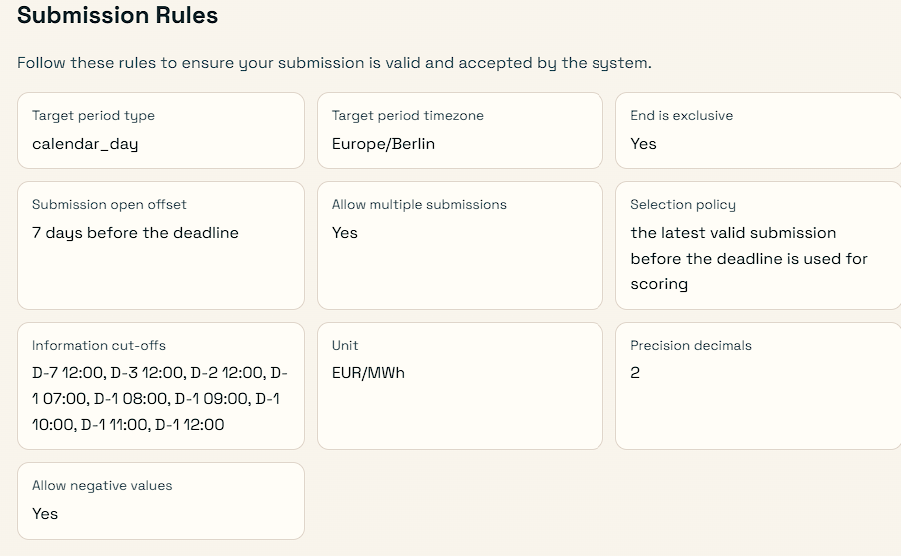

# Challenge

In [292]:
# 1. Fix timestamp order (start must be BEFORE end)
start_ts = pd.Timestamp("2026-06-01 12:00", tz="UTC")
end_ts = pd.Timestamp("2026-10-31 23:59", tz="UTC")

# 2. Pass "DE_LU" correctly into the function call
DELU_data = fetch_entsoe_market_data(start=start_ts, end=end_ts, country_code="DE_LU")
display(DELU_data.head())

Fetching data for DE_LU from 2026-06-01 12:00:00+00:00 to 2026-10-31 23:59:00+00:00...
Unified Dataset Compiled Successfully. Shape: (14640, 19)


,price,load,"(Hydro Pumped Storage, Actual Consumption)","(Biomass, Actual Aggregated)","(Fossil Brown coal/Lignite, Actual Aggregated)","(Fossil Coal-derived gas, Actual Aggregated)","(Fossil Gas, Actual Aggregated)","(Fossil Hard coal, Actual Aggregated)","(Fossil Oil, Actual Aggregated)","(Geothermal, Actual Aggregated)","(Hydro Pumped Storage, Actual Aggregated)","(Hydro Run-of-river and pondage, Actual Aggregated)","(Hydro Water Reservoir, Actual Aggregated)","(Other renewable, Actual Aggregated)","(Solar, Actual Aggregated)","(Waste, Actual Aggregated)","(Wind Offshore, Actual Aggregated)","(Wind Onshore, Actual Aggregated)","(Other, Actual Aggregated)"
2026-06-01 14:00:00+02:00,86.35,55749.37313,4955.8119,3096.901768,4117.78741,329.58167,2366.27643,1147.59024,379.913,19.969,6.1060,1630.71002,20.8728,81.259488,46150.150684,666.0781,544.732,2478.798940,134.73963
2026-06-01 14:15:00+02:00,86.95,55192.26108,4953.8544,3105.579212,4072.65402,318.04067,2376.77740,1207.75250,379.913,19.912,6.1677,1626.92182,20.3054,80.798516,45622.341040,662.8932,545.033,2531.204300,134.73963
2026-06-01 14:30:00+02:00,86.61,54878.19102,4957.4102,3121.209380,4087.34909,326.19801,2366.93430,1243.39253,379.913,19.984,6.1645,1602.53262,20.3649,80.938272,45042.480880,657.0652,533.005,2529.321364,134.73963
2026-06-01 14:45:00+02:00,89.88,55201.54442,4772.7761,3126.280868,4141.86165,320.48301,2422.51833,1256.20524,379.913,19.622,6.2125,1613.05792,27.2550,82.032928,44396.331244,657.7025,502.810,2595.121428,134.73963
2026-06-01 15:00:00+02:00,86.00,55019.82537,4807.8341,3128.376952,4167.20973,317.67866,2473.09000,1281.54463,379.913,19.432,6.1337,1656.77352,25.6820,82.698560,43701.574484,659.7897,424.798,2520.522024,134.73963


In [263]:
DK1_data = master_data

<Axes: >

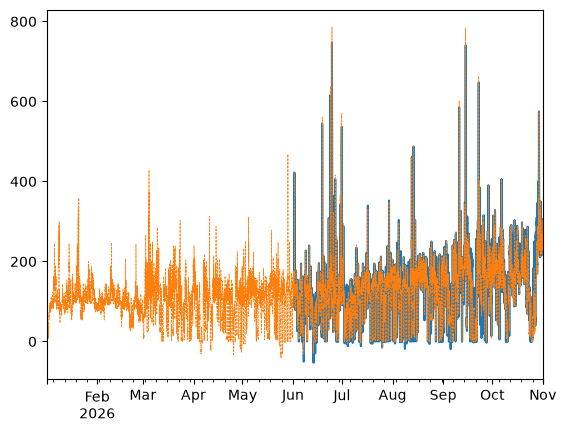

In [269]:
DELU_data["price"].plot()
DK1_data["price"].plot(linestyle = "--", linewidth = 0.5)

feature selection

In [299]:
# 1. Extract DE_LU features using MultiIndex tuples and flatten column names
df_features = DELU_data[[
    ("Fossil Brown coal/Lignite", "Actual Aggregated"), 
    ("Solar", "Actual Aggregated"), 
    ("Wind Onshore", "Actual Aggregated")
]].copy()

df_features.columns = ['lignite', 'solar_de', 'wind_onshore_de']

# 2. Add DE_LU target price and DK1 cross-border price
df_features["price_de"] = DELU_data["price"]
df_features["price_dk"] = DK1_data["price"]

# 3. Construct Discrete Lags
df_features["price_lag_1"] = df_features["price_de"].shift(1)   # 15 mins ago
df_features["price_lag_4"] = df_features["price_de"].shift(4)   # 1 hour ago
df_features["price_lag_96"] = df_features["price_de"].shift(96) # 24 hours ago

df_features["wind_lag_4"] = df_features["wind_onshore_de"].shift(4)
df_features["solar_lag_4"] = df_features["solar_de"].shift(4)
df_features["lignite_lag_4"] = df_features["lignite"].shift(4)

df_features["dk1_lag_1"] = df_features["price_dk"].shift(1)
df_features["dk1_lag_4"] = df_features["price_dk"].shift(4)

# 4. Construct Rolling Momentum Features
df_features["price_rolling_mean_4"] = df_features["price_de"].shift(1).rolling(window=4).mean()
df_features["price_rolling_std_4"] = df_features["price_de"].shift(1).rolling(window=4).std()
df_features["wind_rolling_mean_4"] = df_features["wind_onshore_de"].shift(1).rolling(window=4).mean()

# Drop rows containing NaNs created by shifting and rolling
df_features = df_features.dropna()

# 5. Define your complete feature column set for the model
feature_cols = [
    "lignite", "solar_de", "wind_onshore_de", "price_dk",
    "price_lag_1", "price_lag_4", "price_lag_96",
    "wind_lag_4", "solar_lag_4", "lignite_lag_4",
    "dk1_lag_1", "dk1_lag_4",
    "price_rolling_mean_4", "price_rolling_std_4", "wind_rolling_mean_4"
]

target_col = "price_de"

X = df_features[feature_cols].values
y = df_features[target_col].values
print(f"Feature matrix compiled successfully. Shape: {X.shape}")

Feature matrix compiled successfully. Shape: (14544, 15)


In [300]:
df_features

,lignite,solar_de,wind_onshore_de,price_de,price_dk,price_lag_1,price_lag_4,price_lag_96,wind_lag_4,solar_lag_4,lignite_lag_4,dk1_lag_1,dk1_lag_4,price_rolling_mean_4,price_rolling_std_4,wind_rolling_mean_4
2026-06-02 14:00:00+02:00,3414.80272,38854.533172,8380.563492,84.91,85.31,87.62,80.09,86.35,8288.389828,40728.917188,4447.29618,87.84,80.290000,84.9575,3.348416,8626.709878
2026-06-02 14:15:00+02:00,3379.53512,38744.930420,8584.017396,89.21,89.24,84.91,85.60,86.95,8686.057688,40370.211552,4037.82607,85.31,85.810000,86.1625,1.174347,8649.753294
2026-06-02 14:30:00+02:00,3412.89999,37591.506520,8866.185324,92.50,92.54,89.21,86.52,86.61,8805.323384,39992.909276,3658.53606,89.24,86.730000,87.0650,1.812006,8624.243221
2026-06-02 14:45:00+02:00,3488.57696,35846.204700,9383.978292,96.51,96.53,92.50,87.62,89.88,8727.068612,39281.822584,3528.31387,92.54,87.840000,88.5600,3.170289,8639.458706
2026-06-02 15:00:00+02:00,3590.59374,34447.061648,9450.281884,91.88,91.90,96.51,84.91,86.00,8380.563492,38854.533172,3414.80272,96.53,85.310000,90.7825,4.923179,8803.686126
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-31 23:45:00+01:00,13249.57528,0.060000,5497.545490,232.26,232.26,244.01,253.75,224.20,5807.711580,0.077000,13357.02914,244.01,253.750000,250.2475,7.038515,5717.899077
2026-11-01 00:00:00+01:00,13285.09098,0.000000,5439.076060,257.39,257.39,232.26,258.46,254.82,5760.222030,0.077000,13321.54092,232.26,258.460000,244.8750,10.715249,5640.357555
2026-11-01 00:15:00+01:00,13307.40422,0.000000,5351.709760,251.04,251.04,257.39,244.77,246.24,5711.398120,0.069000,13252.43992,257.39,244.770004,244.6075,10.267042,5560.071062
2026-11-01 00:30:00+01:00,13298.29319,0.000000,5349.831280,239.71,239.71,251.04,244.01,237.10,5592.264580,0.060000,13244.29367,251.04,244.010000,246.1750,10.766598,5470.148973


Training Samples: 14448
Testing Samples:  96

Local Validation Results:
Test RMSE: 9.36 €/MWh
Test MAE:  7.19 €/MWh


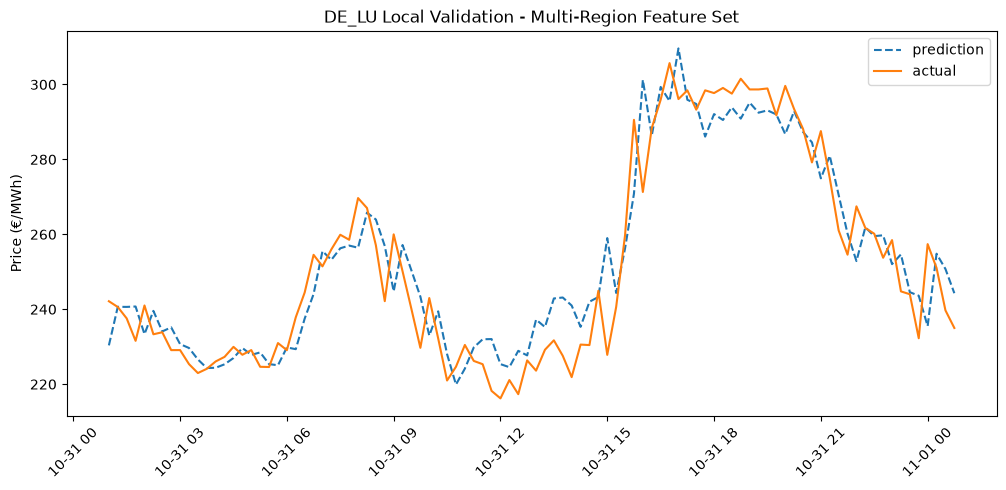

In [355]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# 1. Feature Engineering (Using your selected 15 features)
df_features = DELU_data[[
    ("Fossil Brown coal/Lignite", "Actual Aggregated"), 
    ("Solar", "Actual Aggregated"), 
    ("Wind Onshore", "Actual Aggregated")
]].copy()

df_features.columns = ['lignite', 'solar_de', 'wind_onshore_de']

df_features["price_de"] = DELU_data["price"]
#df_features["price_dk"] = DK1_data["price"]

df_features["price_lag_1"] = df_features["price_de"].shift(1)
df_features["price_lag_4"] = df_features["price_de"].shift(4)
df_features["price_lag_96"] = df_features["price_de"].shift(96)

df_features["wind_lag_4"] = df_features["wind_onshore_de"].shift(4)
df_features["solar_lag_4"] = df_features["solar_de"].shift(4)
df_features["lignite_lag_4"] = df_features["lignite"].shift(4)

#df_features["dk1_lag_1"] = df_features["price_dk"].shift(1)
#df_features["dk1_lag_4"] = df_features["price_dk"].shift(4)

df_features["price_rolling_mean_4"] = df_features["price_de"].shift(1).rolling(window=4).mean()
df_features["price_rolling_std_4"] = df_features["price_de"].shift(1).rolling(window=4).std()
df_features["wind_rolling_mean_4"] = df_features["wind_onshore_de"].shift(1).rolling(window=4).mean()

df_features = df_features.dropna()

feature_cols = [
    "lignite", "solar_de", "wind_onshore_de",
    "price_lag_1", "price_lag_4", "price_lag_96",
    "wind_lag_4", "solar_lag_4", "lignite_lag_4",
 #   "dk1_lag_1", "dk1_lag_4",
    "price_rolling_mean_4", "price_rolling_std_4", "wind_rolling_mean_4"
]

target_col = "price_de"

X = df_features[feature_cols].values
y = df_features[target_col].values

# 2. Train/Test Split (Hold out last 96 steps / 1 day)
steps_per_hour = 4
test_horizon = 24 * steps_per_hour
test_start_idx = len(X) - test_horizon

X_train, y_train = X[:test_start_idx], y[:test_start_idx]
X_test, y_test = X[test_start_idx:], y[test_start_idx:]

print(f"Training Samples: {len(X_train)}")
print(f"Testing Samples:  {len(X_test)}")

# 3. Independent Scaling
scaler_x = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_x.fit_transform(X_train)
X_test_scaled = scaler_x.transform(X_test)
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1))

X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)

# 4. Neural Network Architecture
class RobustPricePredictor(nn.Module):
    def __init__(self, input_dim):
        super(RobustPricePredictor, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(64, 32),
            nn.LayerNorm(32),
            nn.LeakyReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.net(x)

model = RobustPricePredictor(input_dim=X.shape[1])
criterion = nn.HuberLoss(delta=1.0)
optimizer = optim.AdamW(model.parameters(), lr=0.003, weight_decay=1e-4)

# 5. Training Loop
model.train()
for epoch in range(200):
    optimizer.zero_grad()
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()

# 6. Local Evaluation
model.eval()
with torch.no_grad():
    preds_scaled = model(X_test_t)
    preds = scaler_y.inverse_transform(preds_scaled.numpy()).flatten()
    
    rmse = np.sqrt(np.mean((preds - y_test) ** 2))
    mae = np.mean(np.abs(preds - y_test))

print(f"\nLocal Validation Results:")
print(f"Test RMSE: {rmse:.2f} €/MWh")
print(f"Test MAE:  {mae:.2f} €/MWh")

# 7. Plot Results
test_timestamps = df_features.index[test_start_idx:]

plt.figure(figsize=(12, 5))
plt.plot(test_timestamps, preds, label="prediction", linestyle="--")
plt.plot(test_timestamps, y_test, label="actual")
plt.legend()
plt.title("DE_LU Local Validation - Multi-Region Feature Set")
plt.ylabel("Price (€/MWh)")
plt.xticks(rotation=45)
plt.show()

In [304]:
DE_LU_values_public = {
  "challenge_id": "2",
  "target_start": "2026-11-01T00:00:00+01:00",
  "values": [
    257.39,
    251.04,
    239.71,
    235,
    251.5,
    243.85,
    242.64,
    239.87,
    251.39,
    246.74,
    241.7,
    233.4,
    240,
    235.74,
    238.14,
    237.41,
    237.74,
    238.13,
    236.76,
    238.39,
    239.42,
    239.4,
    241.96,
    240.14,
    238.38,
    242.57,
    243,
    246.74,
    250.34,
    250.35,
    247.83,
    242.57,
    255.99,
    251.59,
    245.11,
    236.98,
    249.94,
    237.1,
    235.23,
    232.66,
    248.64,
    247.65,
    246.65,
    240.69,
    249.93,
    244.67,
    245.17,
    235.9,
    242.83,
    241.53,
    240.13,
    244.7,
    241.93,
    238.77,
    252.09,
    253.29,
    234.84,
    229.9,
    244.36,
    259.99,
    230.04,
    253.63,
    275.55,
    308.92,
    278.9,
    292.42,
    304.03,
    306,
    309.16,
    298.84,
    300.78,
    299,
    300.44,
    300.44,
    300,
    299.28,
    301.77,
    295.13,
    296.1,
    297.68,
    303,
    288.99,
    282.48,
    264.53,
    278.91,
    263.82,
    259.2,
    247.99,
    259.81,
    250.92,
    250,
    242.57,
    243.36,
    236.69,
    232.65,
    226.38
  ]
}

In [ ]:
DE_LU_values_public["values"] 

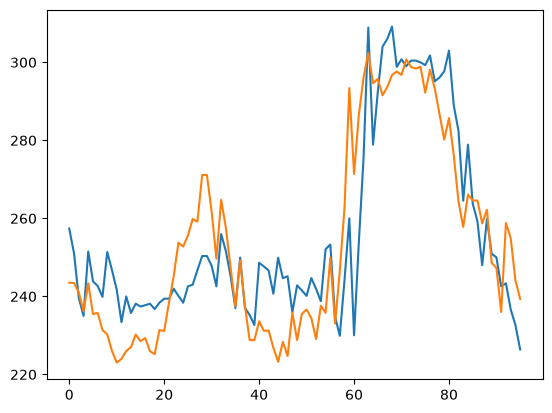

In [310]:
plt.plot(DE_LU_values_public["values"])
plt.plot(preds)

In [321]:
# Save model state dictionary and scalers
torch.save(model.state_dict(), "robust_price_predictor.pth")

In [356]:
%run custom_model.py

In [359]:
%run run_forecast_model.py --challenge_id 2 --save_payload germany_payload.json

Target start defaulted to 2026-11-03T00:00:00+01:00 from API next_target_start 2026-11-03T00:00:00+01:00
Local forecast payload created successfully (challenge_id=2, file=C:\Users\Pulin\Desktop\energy-arena-participate\germany_payload.json).
Target start: 2026-11-03T00:00:00+01:00
No submission was sent. Inspect the file and then use submit_forecast_to_energy_arena.py.


In [360]:
import json
import pandas as pd

# 1. Load the generated JSON payload
with open("germany_payload.json", "r") as f:
    payload = json.load(f)

# 2. Convert the forecast values into a clean pandas DataFrame for inspection
df_forecast = pd.DataFrame(payload)
display(df_forecast.head(24))

,challenge_id,target_start,values
0,2,2026-11-03T00:00:00+01:00,237.783325
1,2,2026-11-03T00:00:00+01:00,241.966492
2,2,2026-11-03T00:00:00+01:00,240.663361
3,2,2026-11-03T00:00:00+01:00,238.608231
4,2,2026-11-03T00:00:00+01:00,229.725494
5,2,2026-11-03T00:00:00+01:00,231.899673
6,2,2026-11-03T00:00:00+01:00,231.258484
7,2,2026-11-03T00:00:00+01:00,227.662109
8,2,2026-11-03T00:00:00+01:00,230.872375
9,2,2026-11-03T00:00:00+01:00,231.210098


In [370]:
import pandas as pd

# Define the start of your target day
start_time = pd.Timestamp("2026-11-03T00:00:00+01:00")

# Generate 96 steps spaced by 15 minutes for the 24-hour day
df_forecast["target_start"] = pd.date_range(
    start=start_time, 
    periods=96, 
    freq="15min"
).strftime("%Y-%m-%dT%H:%M:%S%z")

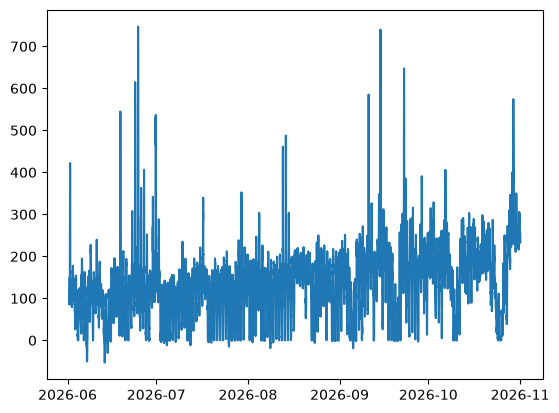

In [381]:
plt.plot(DELU_data["price"])

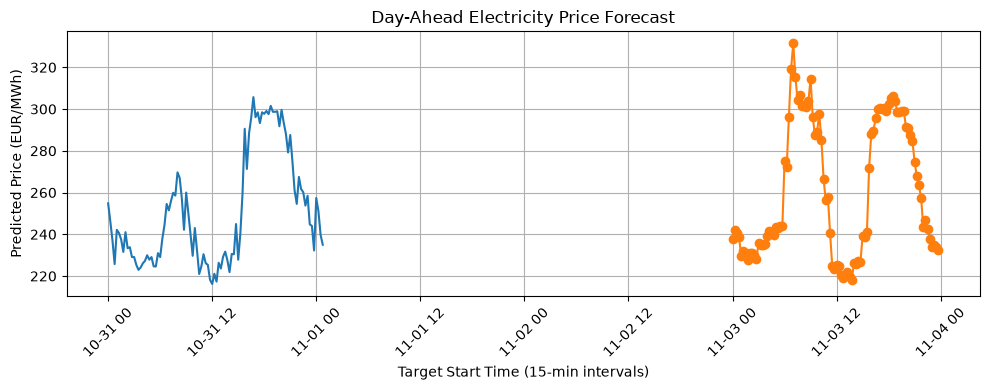

In [387]:
import matplotlib.pyplot as plt
import pandas as pd

# Convert target_start to datetime for proper chronological plotting
x_dates = pd.to_datetime(df_forecast["target_start"])

# Replace 'forecast_price' with whatever column name holds your actual predicted values
y_values = df_forecast["values"] 

plt.figure(figsize=(10, 4))
plt.plot(DELU_data["price"]["2026-10-31":])
plt.plot(x_dates, y_values, marker="o", linestyle="-")
plt.xlabel("Target Start Time (15-min intervals)")
plt.ylabel("Predicted Price (EUR/MWh)")
plt.title("Day-Ahead Electricity Price Forecast")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()